# Proyecto 1. Monitoreo transaccional

Angel Herrarte y Jorge López. Deep Learning 2026, Universidad del Valle.

## 1. Qué estamos preguntando

El Banco del Altiplano ya tiene un motor antifraude, y funciona. Corre sobre variables
agregadas: monto promedio de las últimas 24 horas, transacciones por hora, monto máximo
del día, cuántos comercios distintos. Lo que dice el área de riesgos es que cuando
revisan los casos que se les escaparon, el patrón sí estaba, pero en el orden de las
transacciones y no en los montos.

Entonces la pregunta no es si podemos entrenar una red recurrente. Es si el orden trae
información que los agregados no tienen, en qué casos la trae, y cuánto vale eso en
quetzales.

### Cómo montamos el experimento

Tres modelos que reciben la misma información con distinta forma, sobre la misma
ventana de 20 transacciones de la tarjeta:

| | Qué recibe |
|---|---|
| A, la línea base | los agregados de la ventana, ya resumidos |
| B, el secuencial | los 20 eventos en orden, sin resumir |
| C, nuestra apuesta | las dos cosas |

Ninguno ve nada que el otro no tenga. Si a A le diéramos menos, ganarle no probaría
nada sobre el orden, solo probaría que a B le dimos más datos.

Cada modelo puntúa una transacción en el momento de autorizarla. Elegimos esa unidad
porque es lo que hace el motor actual, y porque los costos del enunciado están dados
por transacción: Q4,200 si se escapa un fraude, Q180 si bloqueamos una compra
legítima.

In [1]:
import numpy as np
import pandas as pd
import torch

from src.config import ConfigGenerador, COSTO_FN, COSTO_FP, CARTERA_TARJETAS, K
from src.generador import generar
from src.ventanas import construir_dataset
from src.modelos import verificar_senuelo
from src.experimento import ejecutar_experimento, guardar_artefactos, MARGEN_EXITO_C
from src import figuras

pd.set_option("display.width", 120)
config = ConfigGenerador()
print(f"semilla={config.semilla}  tarjetas={config.n_tarjetas}  dias={config.n_dias}  K={K}")

semilla=42  tarjetas=6000  dias=180  K=20


## 2. Los datos

Fuimos por la Ruta A y generamos los datos nosotros. La razón no es que sea más fácil.
Es que así sabemos qué mecanismo produjo cada fraude, y eso nos deja medir el
desempeño mecanismo por mecanismo. Con datos reales no hay forma: la etiqueta dice
"fraude" y ya. Esa tabla, la de la sección 10, terminó siendo lo más útil que sacamos
del trabajo.

Generamos cuatro mecanismos, y los elegimos a propósito para que el resultado no
saliera parejo:

| | Cómo se ve | ¿El orden importa? |
|---|---|---|
| F1, prueba y cobro | tres a seis compritas de Q5 a Q40 en cuestión de minutos, y después una compra de Q2,000 a Q8,000 | sí |
| F2, viaje imposible | dos transacciones en ciudades lejanas separadas por minutos | a medias |
| F3, toma de cuenta | ráfaga de ecommerce caro, de madrugada, en rubros que la tarjeta nunca usó | no |
| F4, goteo lento | cargos chicos del mismo comercio cada pocos días | lo dejamos fuera del entrenamiento |

### El señuelo

Si F1 fuera nada más "varias compras chiquitas y luego una grande", los agregados lo
resolverían solos y no habría nada que investigar. Por eso generamos también un
señuelo legítimo: las mismas compritas, los mismos huecos entre ellas, los mismos
rubros y la misma compra grande al final. Lo único distinto es que en el fraude las
compritas van de menor a mayor y en el señuelo van revueltas.

Esa rampa es la firma del ataque. El que roba la tarjeta va probando montos cada vez
más altos para ver hasta dónde aguanta antes de cobrar. Alguien que legítimamente hace
tres gastos chicos y después uno grande no los hace en orden creciente.

Los dos episodios terminan en la compra grande, y eso costó una iteración entenderlo.
Nuestro primer diseño invertía el episodio completo, con la compra grande al inicio.
Falló la verificación de la sección 7 con ROC-AUC de 1.000, porque los agregados se
calculan por transacción y no por episodio: al poner la compra grande primero, se
metía en la historia de todas las anclas siguientes y `monto_max_ventana` pasaba de
185 a 3,830. Terminando los dos en la compra grande, en esa última transacción la
historia trae los mismos montos y los mismos huecos en ambos casos.

F4 aparece solo en el conjunto de prueba. Nos sirve para dos cosas: es la segunda
prueba de falsificación, con un mecanismo que el modelo nunca vio, y es el caso donde
dijimos de antemano que íbamos a fallar.

In [2]:
df = generar(config)
datos = construir_dataset(df, config)

print(f"{len(df):,} transacciones · {df['id_tarjeta'].nunique():,} tarjetas · {config.n_dias} dias")
print(f"tasa de fraude global: {df['es_fraude'].mean():.4%}\n")

resumen = (df.groupby("mecanismo")
             .agg(transacciones=("id_tx", "size"),
                  monto_medio=("monto", "mean"),
                  monto_max=("monto", "max"),
                  es_fraude=("es_fraude", "max"))
             .sort_values("transacciones", ascending=False))
resumen

484,738 transacciones · 6,000 tarjetas · 180 dias
tasa de fraude global: 0.6562%



,transacciones,monto_medio,monto_max,es_fraude
mecanismo,,,,
legitimo,480542,76.044086,3987.99,0
F1,1260,926.987444,7928.92,1
F3,1028,2966.300107,4998.28,1
senuelo_f1,1015,901.042118,7996.25,0
F2,720,95.519139,688.78,1
F4,173,139.602832,199.30,1


## 3. Lo que apostamos con C, escrito antes de entrenar

Esta celda se escribió antes de que existiera código de modelos. El diseño que la
contiene está en `docs/superpowers/specs/` y quedó en el historial de git con fecha
anterior.

> Creemos que combinar el estado oculto del GRU con las variables agregadas va a
> mejorar el AUC-PR en validación, porque cada representación cubre un mecanismo
> distinto: los agregados agarran F3, que es una anomalía de monto y contexto, y la
> secuencia agarra F1, que es una anomalía de orden. Ninguno de los dos cubre los dos.
>
> Lo vamos a dar por útil si el híbrido le saca al mejor de A y B por lo menos 0.02 de
> AUC-PR absoluto en validación, y si esa mejora se sostiene al mirar el desglose por
> mecanismo, o sea que no venga toda de un solo tipo de fraude.

La segunda condición nos pareció necesaria. Sin ella, una mejora concentrada en F1
contaría como éxito sin haber demostrado que las dos representaciones se complementan,
que es lo que estamos afirmando.

De control usamos A y B por separado, sobre los mismos datos y la misma partición.

In [3]:
print(f"margen de exito declarado: {MARGEN_EXITO_C:+.3f} de AUC-PR en validacion")

margen de exito declarado: +0.020 de AUC-PR en validacion


## 4. Correr el experimento

Una sola llamada entrena los tres modelos, corre las dos permutaciones, elige los
umbrales con validación y al final lee prueba una vez.

`leer_prueba=True` se prende aquí y en ningún otro lado. Para cuando llega a esta
celda, la arquitectura, el umbral y el criterio de la apuesta ya están fijos en el
código.

In [4]:
resultados = ejecutar_experimento(config, epocas=12, semilla=42,
                                 leer_prueba=True, verbose=True)
guardar_artefactos(resultados, config)
print("\nartefactos guardados en artefactos/")

go/no-go senuelo ROC-AUC = 0.6171


A entrenado | AUC-PR val = 0.8101


B entrenado | AUC-PR val = 0.8822


C entrenado | AUC-PR val = 0.8566


permutacion P1 | B = 0.6780 | C = 0.7049


permutacion P2 | B = 0.0180 | C = 0.1328



artefactos guardados en artefactos/


## 5. De dónde salen los datos y cómo los partimos (evidencia 1)

La partición respeta el tiempo. Lo más viejo entrena, lo de en medio valida, lo último
prueba. Entre bloque y bloque dejamos dos días de embargo que se botan, para que
ningún episodio de fraude quede partido justo en la frontera.

Las mismas tarjetas salen en los tres bloques, y eso está bien: partimos por tiempo, no
por cliente. Una ventana anclada en validación sí puede leer historia del período de
entrenamiento, porque eso es el pasado de esa transacción, no es fuga.

,transacciones,fraudes,tasa,dia_min,dia_max
particion,,,,,
entrenamiento,322903,1948,0.0060,0.0008,119.9997
embargo,10840,95,0.0088,120.0007,151.9969
validacion,75536,518,0.0069,122.0014,149.9997
prueba,75459,620,0.0082,152.0034,179.9984


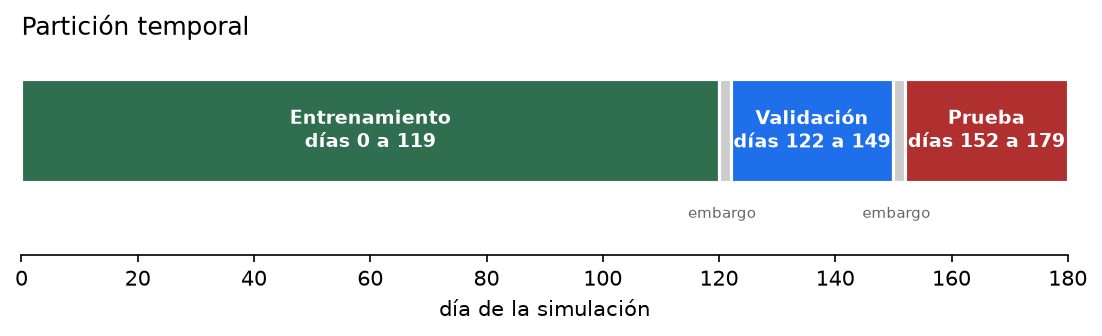

In [5]:
tabla = (datos.meta.groupby("particion")
         .agg(transacciones=("id_tx", "size"),
              fraudes=("es_fraude", "sum"),
              tasa=("es_fraude", "mean"),
              dia_min=("marca_tiempo", "min"),
              dia_max=("marca_tiempo", "max"))
         .reindex(["entrenamiento", "embargo", "validacion", "prueba"]))
display(tabla.round(4))

figuras.fig_particion(config)
from IPython.display import Image, display as _d
_d(Image("figuras/fig1_particion.png"))

Una cosa que hay que decir de esta tabla: prueba tiene más fraude que validación,
porque ahí es donde metimos F4. Lo hicimos a propósito, pero tiene una consecuencia.
Como el AUC-PR depende de qué tan frecuente sea la clase positiva, comparar el AUC-PR
de validación contra el de prueba no significa gran cosa. Comparar A contra B contra C
sobre el mismo conjunto de prueba sí, y es la comparación que nos importa.

## 6. Que no se nos cuele información del futuro

Cada uno de estos responde a una penalización de la rúbrica. Los dejamos como `assert`
para que el notebook reviente si alguien rompe uno más adelante.

In [6]:
from src.ventanas import ajustar_escaladores, ajustar_escaladores_agregados

ent = (datos.meta["particion"] == "entrenamiento").to_numpy()
todo = np.ones(len(datos.meta), dtype=bool)

# 1. los escaladores se ajustan solo con entrenamiento
e_ent = ajustar_escaladores(datos.seq_num, datos.mascara, ent)
e_todo = ajustar_escaladores(datos.seq_num, datos.mascara, todo)
assert not np.allclose(e_ent["medias"], e_todo["medias"])
print("ok  los escaladores de entrenamiento no coinciden con los del conjunto completo")

# 2. la particion es temporal, no aleatoria
for antes, despues in [("entrenamiento", "validacion"), ("validacion", "prueba")]:
    assert (datos.meta.loc[datos.meta.particion == antes, "marca_tiempo"].max()
            < datos.meta.loc[datos.meta.particion == despues, "marca_tiempo"].min())
print("ok  los bloques no se traslapan en el tiempo")

# 3. los agregados solo miran hacia atras
prueba = pd.DataFrame({"id_tx": [0, 1, 2, 3], "id_tarjeta": 7,
                       "marca_tiempo": [10.0, 10.5, 10.75, 11.0],
                       "monto": [100.0, 200.0, 300.0, 900.0],
                       "rubro": "ropa", "canal": "chip", "ciudad": "guatemala",
                       "es_fraude": 0, "mecanismo": "legitimo", "id_episodio": -1})
d_prueba = construir_dataset(prueba, config)
assert d_prueba.agregados.loc[3, "monto_max_ventana"] == 300.0   # y no 900
print("ok  el ancla no entra en su propia ventana")

# 4. F4 no aparece antes de prueba
assert not datos.meta[(datos.meta.mecanismo == "F4")
                      & (datos.meta.particion != "prueba")].shape[0]
print("ok  F4 existe unicamente en prueba")

# 5. los umbrales salen de validacion
from src.evaluacion import barrer_umbrales, costo_esperado
y_val = resultados.puntajes_validacion["y"]
for m in ["A", "B", "C"]:
    p, u = resultados.puntajes_validacion[m], resultados.umbrales[m]
    assert np.isclose(costo_esperado(y_val, p, u), barrer_umbrales(y_val, p)["costo"].min())
print("ok  cada umbral minimiza el costo en validacion, no en prueba")

ok  los escaladores de entrenamiento no coinciden con los del conjunto completo
ok  los bloques no se traslapan en el tiempo
ok  el ancla no entra en su propia ventana
ok  F4 existe unicamente en prueba
ok  cada umbral minimiza el costo en validacion, no en prueba


## 7. ¿El señuelo sirve de algo?

Antes de sacar cualquier conclusión sobre el orden hay que ver si el señuelo cumple.
Entrenamos el boosting con puros agregados y le pedimos que separe F1 del señuelo. Si
pudiera, el experimento entero no valdría nada.

In [7]:
auc_cobro = verificar_senuelo(datos, solo_cobro=True)
auc_todas = verificar_senuelo(datos, solo_cobro=False)

print("ROC-AUC de los agregados separando F1 del senuelo")
print(f"  en el cobro     : {auc_cobro:.4f}")
print(f"  en todas         : {auc_todas:.4f}")
assert auc_cobro <= 0.60, "el senuelo no esta funcionando, hay que recalibrar el generador"
print("\npasa")

ROC-AUC de los agregados separando F1 del senuelo
  en el cobro     : 0.5386
  en todas         : 0.6171

pasa


Que los dos números no coincidan no es un problema, y de hecho terminó siendo
interesante.

El diseño solo promete montos y huecos idénticos en la última transacción del episodio,
la del cobro. Ahí los agregados quedan casi en el azar. En las transacciones
intermedias sí queda algo de señal, y sabemos por qué: como F1 es una rampa, sus
primeras compritas siempre son las más chicas, mientras que las del señuelo van
revueltas.

Dicho para el comité: los agregados alcanzan a ver parte del reconocimiento, pero se
quedan ciegos justo en el cobro, que es donde están los Q2,000 a Q8,000.

## 8. A contra B (evidencia 2)

Mismos datos, misma partición, mismo horizonte. Reportamos AUC-PR. La exactitud no la
usamos como métrica principal porque con 0.6% de positivos un modelo que nunca alerta
sacaría 99.4% y no serviría para nada.

,AUC-PR validacion,AUC-PR prueba,umbral elegido,precision,exhaustividad,F1
A,0.8101,0.5486,0.7990,0.4383,0.6532,0.5246
B,0.8822,0.6103,0.6482,0.4797,0.6855,0.5644
C,0.8566,0.5999,0.3065,0.4408,0.6661,0.5305



B le saca +0.0721 de AUC-PR a A en validacion


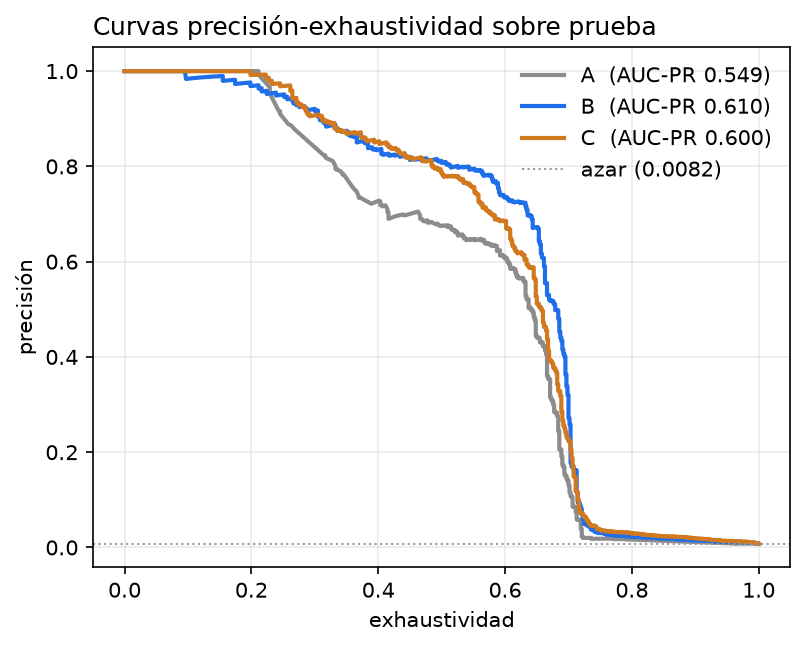

In [8]:
comparacion = pd.DataFrame({
    m: {"AUC-PR validacion": resultados.auc_pr[m]["validacion"],
        "AUC-PR prueba": resultados.auc_pr[m]["prueba"],
        "umbral elegido": resultados.umbrales[m],
        "precision": resultados.metricas_prueba[m]["precision"],
        "exhaustividad": resultados.metricas_prueba[m]["exhaustividad"],
        "F1": resultados.metricas_prueba[m]["f1"]}
    for m in ["A", "B", "C"]}).T
display(comparacion.round(4))

margen = resultados.auc_pr["B"]["validacion"] - resultados.auc_pr["A"]["validacion"]
print(f"\nB le saca {margen:+.4f} de AUC-PR a A en validacion")

figuras.fig_curvas_pr(resultados.puntajes_prueba["y"],
                      {m: resultados.puntajes_prueba[m] for m in ["A", "B", "C"]},
                      {m: resultados.auc_pr[m]["prueba"] for m in ["A", "B", "C"]},
                      "Curvas precisión-exhaustividad sobre prueba")
_d(Image("figuras/fig2_curvas_pr.png"))

## 9. Permutación controlada (evidencia 3, primera parte)

Que las métricas suban no prueba que el modelo esté usando el orden. Podría estar
aprovechando cualquier otra cosa. Así que tratamos de tumbar nuestra propia conclusión:
barajamos el orden dentro de cada secuencia sin cambiar los eventos ni los agregados, y
volvemos a evaluar.

Hicimos dos versiones. En P1 barajamos solo la historia y dejamos la transacción actual
en su lugar, que aísla la pregunta de si importa el orden de lo anterior. En P2
barajamos las 20 posiciones y no queda orden de nada.

También sirve de control de que no la estamos regando: el AUC-PR de A tiene que quedar
igual, porque sus agregados no dependen del orden. Si se moviera, el que está mal es
nuestro código de permutación.

ok  permutar no mueve a A



,original,P1 historia barajada,P2 orden destruido,caida P1,caida P2
A,0.8101,0.8101,0.8101,0.0000,0.0000
B,0.8822,0.6780,0.0180,-0.2042,-0.8642
C,0.8566,0.7049,0.1328,-0.1517,-0.7238


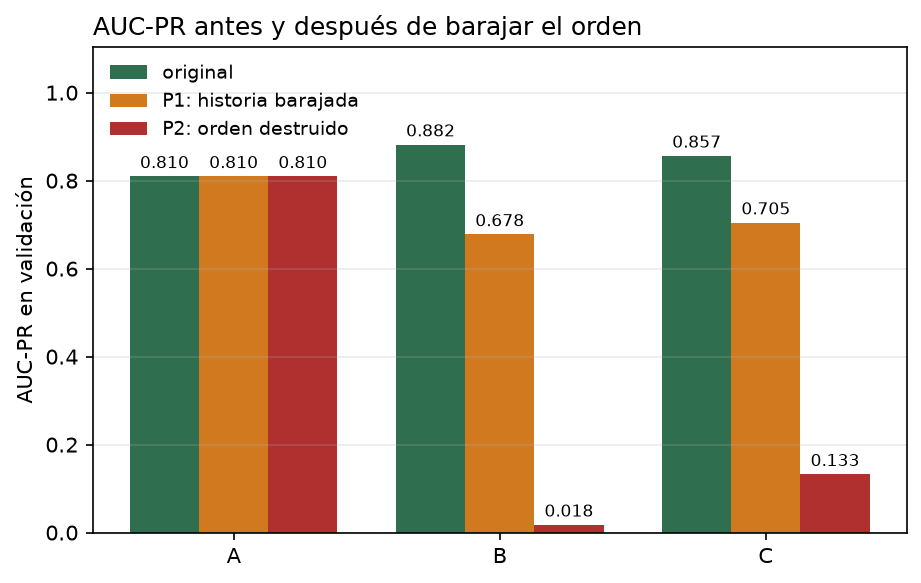

In [9]:
# si A se mueve bajo permutacion, el error es nuestro
for variante in ["P1", "P2"]:
    assert abs(resultados.permutacion["A"][variante]
               - resultados.auc_pr["A"]["validacion"]) < 1e-12
print("ok  permutar no mueve a A\n")

perm = pd.DataFrame({
    m: {"original": resultados.auc_pr[m]["validacion"],
        "P1 historia barajada": resultados.permutacion[m]["P1"],
        "P2 orden destruido": resultados.permutacion[m]["P2"]}
    for m in ["A", "B", "C"]}).T
perm["caida P1"] = perm["P1 historia barajada"] - perm["original"]
perm["caida P2"] = perm["P2 orden destruido"] - perm["original"]
display(perm.round(4))

figuras.fig_permutacion({m: resultados.auc_pr[m]["validacion"] for m in ["A", "B", "C"]},
                        resultados.permutacion)
_d(Image("figuras/fig3_permutacion.png"))

B pierde buena parte de su desempeño con solo barajar la historia, y se cae por
completo cuando destruimos el orden. A no se mueve ni un decimal. Con esto sí podemos
decir que el modelo secuencial está usando el orden.

Vale explicar un detalle raro. Bajo P2 el AUC-PR de B queda por debajo del azar. No es
solo ruido: al sacar la transacción actual de la última posición, el modelo lee una
cualquiera como si fuera la que está autorizando, así que se equivoca de forma
sistemática y no al azar.

## 10. Mecanismo por mecanismo, y el que nunca vio (evidencia 3, segunda parte)

Nuestra segunda prueba de falsificación es un mecanismo de fraude que el modelo jamás
vio: F4, el goteo lento, existe solo en prueba.

Esta es la tabla que más nos sirvió, sobre todo porque el resultado no sale parejo. Si
B ganara en todo habría que desconfiar del generador.

,A,B,C,n,orden
mecanismo,,,,,
F1,0.801,0.896,0.839,211,si
F2,1.000,1.000,1.000,103,a medias
F3,1.000,1.000,1.000,133,no
F4,0.000,0.000,0.000,173,no entrenado


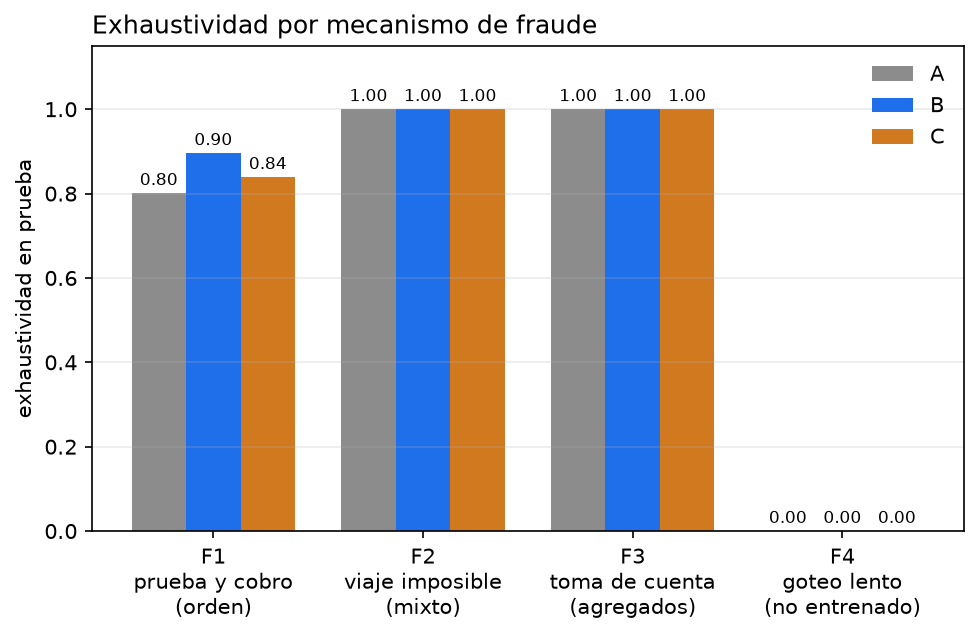

In [10]:
desglose = pd.DataFrame({m: resultados.desglose[m]["exhaustividad"]
                         for m in ["A", "B", "C"]})
desglose["n"] = resultados.desglose["B"]["n"]
desglose["orden"] = ["si", "a medias", "no", "no entrenado"]
display(desglose.round(3))

figuras.fig_desglose({m: resultados.desglose[m] for m in ["A", "B", "C"]})
_d(Image("figuras/fig4_desglose.png"))

Leyendo la tabla por partes:

En F3, que no depende del orden, A empata con B. Esto es lo que le da credibilidad a
todo lo demás, porque muestra que la línea base no está amañada: donde los agregados
alcanzan, alcanzan.

En F1, que sí depende del orden, B le gana a A. Y es el único lugar donde le gana, que
es exactamente donde dijimos que iba a ganar.

En F2 quedan prácticamente iguales, como esperábamos.

En F4 fallan los tres. Lo habíamos anticipado y lo dejamos así: es el punto ciego
conocido del sistema.

Que F1 sea el único mecanismo donde B gana, y que sea justo el que construimos para
depender del orden, es difícil de atribuir a la casualidad.

## 11. Cómo nos fue con la apuesta (evidencia 4)

Volvemos a lo que escribimos en la sección 3 y lo comparamos con el criterio que
habíamos fijado.

In [11]:
v = resultados.veredicto_c
mejor_ab = max(resultados.auc_pr["A"]["validacion"], resultados.auc_pr["B"]["validacion"])
print(f"mejor de A y B en validacion : {mejor_ab:.4f}")
print(f"C en validacion              : {resultados.auc_pr['C']['validacion']:.4f}")
print(f"margen                       : {v['margen']:+.4f}   (haciamos falta {MARGEN_EXITO_C:+.3f})")
print(f"llega al margen              : {v['supera_umbral']}")
print(f"se sostiene por mecanismo    : {v['sostenido_por_mecanismo']}")
print()
print("veredicto:", "util" if v["util"] else "no util, la hipotesis no se cumplio")

mejor de A y B en validacion : 0.8822
C en validacion              : 0.8566
margen                       : -0.0256   (haciamos falta +0.020)
llega al margen              : False
se sostiene por mecanismo    : True

veredicto: no util, la hipotesis no se cumplio


No se cumplió, y así lo reportamos. El híbrido no le sacó a B el margen que
pedimos, de hecho quedó por debajo.

Pensándolo después tiene sentido. El GRU recibe los eventos crudos, así que puede
reconstruir por su cuenta casi cualquier resumen que le pasáramos aparte. Darle los
agregados no le agrega información, le agrega parámetros que tiene que aprender a
ignorar.

Lo dejamos anotado porque es tentador hacer lo contrario: mirar el conjunto de prueba,
ver si ahí C quedó mejor, y reescribir la hipótesis. El criterio se fijó sobre
validación antes de abrir prueba y ahí se queda.

## 12. Dónde poner el umbral y qué recomendamos (evidencias 5 y 6)

Un fraude que se escapa cuesta Q4,200 y bloquear una compra buena cuesta Q180. La
relación es de 23 a 1, así que conviene bloquear de más y el umbral óptimo va a salir
bajo.

Lo elegimos minimizando el costo esperado sobre validación, lo congelamos, y lo
aplicamos una sola vez a prueba.

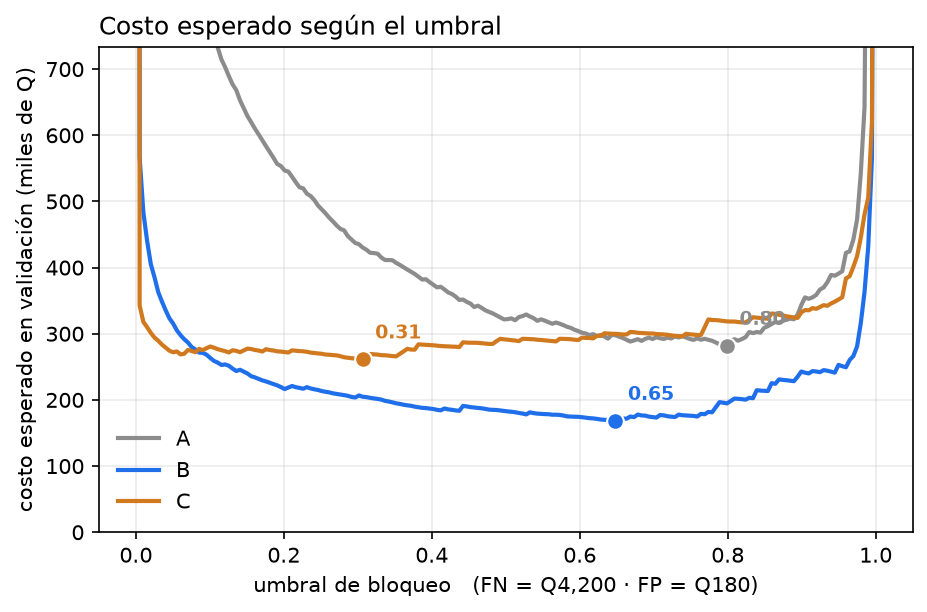

,umbral,fraudes no detectados,legitimas bloqueadas,costo mensual (Q),ahorro vs A (Q)
A,1.0,215.0,519.0,249105000.0,0.0
B,1.0,195.0,461.0,225495000.0,23610000.0
C,0.0,207.0,524.0,240930000.0,8175000.0


B ahorra Q23,610,000 al mes contra A  (9.5% del costo actual)
C ahorra Q8,175,000 al mes contra A  (3.3% del costo actual)


In [12]:
figuras.fig_costo(resultados.puntajes_validacion["y"],
                  {m: resultados.puntajes_validacion[m] for m in ["A", "B", "C"]},
                  resultados.umbrales)
_d(Image("figuras/fig5_costo.png"))

econ = pd.DataFrame({
    m: {"umbral": resultados.umbrales[m],
        "fraudes no detectados": resultados.metricas_prueba[m]["fn"],
        "legitimas bloqueadas": resultados.metricas_prueba[m]["fp"],
        "costo mensual (Q)": resultados.economia[m]["costo_mensual"],
        "ahorro vs A (Q)": resultados.economia[m].get("ahorro_mensual_vs_A", 0.0)}
    for m in ["A", "B", "C"]}).T
display(econ.round(0))

for m in ["B", "C"]:
    ahorro = resultados.economia[m]["ahorro_mensual_vs_A"]
    pct = 100 * ahorro / resultados.economia["A"]["costo_mensual"]
    print(f"{m} ahorra Q{ahorro:,.0f} al mes contra A  ({pct:.1f}% del costo actual)")

Sobre esos quetzales hay que ser honestos: están inflados y no sirven como
pronóstico. Salen de una tasa de fraude simulada del 0.6% de las transacciones, bastante
arriba de la de una cartera real. Lo que sí se sostiene es el porcentaje de ahorro
contra el sistema actual, porque ese no depende de la escala que elegimos.

In [13]:
ahorro_b = resultados.economia["B"]["ahorro_mensual_vs_A"]
gana_orden = resultados.permutacion["B"]["P2"] < resultados.auc_pr["B"]["validacion"] - 0.05
mejora_b = resultados.auc_pr["B"]["validacion"] > resultados.auc_pr["A"]["validacion"]

if mejora_b and gana_orden and ahorro_b > 0:
    print("recomendacion: complementar el motor actual con el modelo secuencial B")
elif mejora_b:
    print("recomendacion: complementar, con reservas sobre el valor del orden")
else:
    print("recomendacion: conservar el sistema actual")

recomendacion: complementar el motor actual con el modelo secuencial B


### Qué recomendamos y hasta dónde llega

Complementar, no reemplazar. La evidencia da para esa palabra y no para otra.

B no le gana a A ni en F2 ni en F3. Cambiar el motor actual por este significaría
perder una defensa que sirve, a cambio de una mejora que solo aparece en F1. Pero en F1
sí le gana con claridad, y F1 es el caro, porque el cobro anda entre Q2,000 y Q8,000.
Lo sensato es correr los dos y quedarse con el puntaje más alto, o meter el puntaje de
B como una variable más del motor que ya existe.

El error concreto que sabemos que tiene es F4. Cargos chicos del mismo comercio cada
pocos días quedan debajo de cualquier umbral de velocidad y ninguno de los tres modelos
los agarra. Eso necesita otra defensa, probablemente algo que busque recurrencia en
ventanas de semanas y no de horas.

Cambiaríamos la recomendación en tres casos. El primero es si resulta que el señuelo no
existe en los datos reales: todo esto depende de que haya clientes legítimos con la
misma firma agregada que un ataque de prueba y cobro, y esa es la primera hipótesis que
habría que ir a verificar contra datos del banco. El segundo es si bloquear cuesta
bastante más que Q180; el umbral sale bajo porque bloquear es barato, y si el costo
reputacional se pareciera al del fraude, el umbral subiría y la ventaja de B se
achicaría. El tercero es que cambien de patrón: F4 ya nos mostró que un mecanismo nuevo
pasa sin que nadie lo vea, porque un modelo supervisado solo defiende contra lo que ya
pasó.

## Matriz de evidencias

| Evidencia | Dónde está | Qué concluimos | Qué la limita |
|---|---|---|---|
| 1. Integridad de datos | §5, fig. 1 | partición temporal con embargo y cinco controles verificados | son datos sintéticos, así que la validez externa depende del generador |
| 2. A contra B | §8, fig. 2 | B le gana a A en AUC-PR con la misma información | el AUC-PR de prueba no es comparable con el de validación, F4 cambia la prevalencia |
| 3. Valor del orden | §9 y §10, fig. 3 y 4 | B se cae al barajar y A no se mueve; la ventaja se concentra en F1 | mide el orden que nosotros construimos, no el del fraude real |
| 4. La apuesta | §11 | no se cumplió, el híbrido no llegó al margen que fijamos | el margen de 0.02 lo elegimos nosotros, no sale de ningún estándar |
| 5. Umbral y costo | §12, fig. 5 | umbral por costo esperado; B ahorra contra A | las cifras absolutas están infladas, solo el porcentaje se sostiene |
| 6. Recomendación | §12 | complementar, no reemplazar; F4 es el punto ciego | se cae si el señuelo no existe en los datos reales |